# Step 1

#### Dataset Inspection

In [1]:
# Import the libraries we need
# Why: json turns each text line into a Python dict; pandas gives us tables (DataFrames).
import json
import pandas as pd

In [2]:
# Read the raw file line by line (one ticket per line) into a list of dicts
# Why: reading it ourselves means nothing is converted or changed behind our back.
rows = []
with open("data/raw/dataset_clean.jsonl", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            rows.append(json.loads(line))

len(rows)

10000

In [8]:
# Show the first ticket as a Python dict
rows[0]

{'ticket_id': 'TCKT-001-001',
 'created_at': '2026-02-04T22:41:00+02:00',
 'updated_at': '2026-02-05T02:41:00+02:00',
 'channel': 'email',
 'model': 'gemini-3-flash',
 'dialect': 'Egyptian',
 'title_ar': 'السيستم واقع',
 'description_ar': 'يا جماعة السيستم كله مش شغال عند كل الناس في القسم، في عطل عام؟. بقالها 21 ساعة تقريبا. لو محتاجين لوجز أو سكرينشوت أنا جاهز أبعتها.',
 'category_level_1': 'Service',
 'category_level_2': 'Incident',
 'category_level_3': 'Outage',
 'category_path': 'Service > Incident > Outage',
 'tags': ['outage', 'system'],
 'labels_json': {'l1': 'Service',
  'l2': 'Incident',
  'l3': 'Outage',
  'tags': ['outage', 'down', 'system']},
 'impact': 3,
 'urgency': 5,
 'priority': 4,
 'sentiment': 'negative'}

In [3]:
# Turn the list of dicts into a table: one row per ticket, one column per field
# Why: a table lets us count, filter and compare tickets easily.
df = pd.DataFrame(rows)
df.shape

(10000, 18)

In [5]:
# Preview the first 3 rows of the table
df.head(3)

,ticket_id,created_at,updated_at,channel,model,dialect,title_ar,description_ar,category_level_1,category_level_2,category_level_3,category_path,tags,labels_json,impact,urgency,priority,sentiment
0,TCKT-001-001,2026-02-04T22:41:00+02:00,2026-02-05T02:41:00+02:00,email,gemini-3-flash,Egyptian,السيستم واقع,يا جماعة السيستم كله مش شغال عند كل الناس في ا...,Service,Incident,Outage,Service > Incident > Outage,"[outage, system]","{'l1': 'Service', 'l2': 'Incident', 'l3': 'Out...",3,5,4,negative
1,TCKT-001-002,2026-02-10T12:51:00+02:00,2026-02-10T18:51:00+02:00,portal,gemini-3-flash,Egyptian,الأوتلوك بيهنج,كل ما أفتح الأوتلوك بيعمل Not Responding ويقفل...,Software,Email/Calendar,Outlook Issue,Software > Email/Calendar > Outlook Issue,"[outlook, sync]","{'l1': 'Software', 'l2': 'Email/Calendar', 'l3...",4,2,3,neutral
2,TCKT-001-003,2026-02-02T15:25:00+02:00,2026-02-03T10:25:00+02:00,phone,gemini-3-flash,Egyptian,مشكلة في الـ Remote Access,مش عارف أدخل ريموتلي من البيت، الـ VPN بيفصل ك...,Network,VPN,Connection Failure,Network > VPN > Connection Failure,"[tunnel, vpn]","{'l1': 'Network', 'l2': 'VPN', 'l3': 'Connecti...",1,2,2,negative


In [9]:
# README check: count the classes at each category level (expected 6, 16, 48)
for col in ["category_level_1", "category_level_2", "category_level_3"]:
    print(col, df[col].nunique())

category_level_1 6
category_level_2 16
category_level_3 48


In [10]:
# README check: count exact duplicates (same title AND description; expected 451)
df.duplicated(subset=["title_ar", "description_ar"]).sum()

np.int64(451)

##### Data Quality Validation

##### 1

According to the dataset's README, based on the information you provided, the priority is calculated using the following formula:

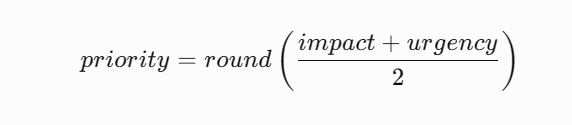

In [ ]:
# README check: is priority = round((impact + urgency) / 2)?
# Why: if priority is computed from urgency, it leaks the urgency label and must not be a model input.
avg = (df["impact"] + df["urgency"]) / 2
print((avg.round() == df["priority"]).mean()) 
#The equation turned out to be correct for 7,692 tickets out of 10,000, and incorrect for 2,308.

0.7692


In [12]:
# How does Python round .5? (banker's rounding: to the nearest even number)
round(2.5), round(3.5)

(2, 4)

In [17]:
# Show tickets where Python's rounding disagrees with the stored priority
# Why: look at the rows behind a surprising number (here: averages of 2.5 and 4.5).
df.loc[avg.round() != df["priority"], ["impact", "urgency", "priority"]].head()

,impact,urgency,priority
3,4,1,3
5,4,5,5
11,3,2,3
15,2,3,3
17,1,4,3


###### Findings
1. `priority` = school rounding of (impact + urgency) / 2 → derived from urgency → excluded from model inputs.
2. 14 of 88 tickets that mention "license" are labeled L3 = Crash → L3 label noise (L2 is not affected).

 
Both "License" and "Crash" fall under "Office Apps." We have already verified that each L3 item has only one parent in L2; therefore, the L2 assignment for all 88 tickets is correct. This error only affects the L3 level—not the level we are currently working on.

In [19]:
# Find tickets that mention "license" and list their L3 labels
# Why: a "License Error" ticket was labeled Crash; check whether that is rare or common.
text = df["title_ar"] + " " + df["description_ar"]
mentions_license = text.str.contains("license", case=False)
print(mentions_license.sum())
df.loc[mentions_license, "category_level_3"].value_counts()

88


category_level_3
License    74
Crash      14
Name: count, dtype: int64

In [ ]:
# Suspect tickets: mention "license" but are labeled L3 = Crash
suspects = df[mentions_license & (df["category_level_3"] == "Crash")]

In [21]:
# Show the full text of the suspect tickets (mention "license" but labeled Crash)
pd.set_option("display.max_colwidth", None)
suspects[["ticket_id", "description_ar"]]

,ticket_id,description_ar
7,TCKT-001-008,الورد والإكسيل بيطلعولي رسالة License Error ومش عارف أشتغل. نسخة الأوفيس: Office 365 v2402. الملفات على Share داخلي. بقالها 36 ساعة تقريبا. محتاج الموضوع يتحل بسرعة لو سمحتوا.
59,TCKT-001-060,الورد والإكسيل بيطلعولي رسالة License Error ومش عارف أشتغل. نسخة الأوفيس: Office 2019. الملفات على Share داخلي. بقالها 47 ساعة تقريبا. جربت ريستارت وكمان عملت Repair بس نفس المشكلة.
68,TCKT-001-069,الورد والإكسيل بيطلعولي رسالة License Error ومش عارف أشتغل. نسخة الأوفيس: Office 2019. الملفات على Share داخلي. بقالها 46 ساعة تقريبا. المشكلة بتظهر وتختفي، ومش ثابتة على طول.
95,TCKT-001-096,الورد والإكسيل بيطلعولي رسالة License Error ومش عارف أشتغل. نسخة الأوفيس: Office 2019. الملفات على Share داخلي. بقالها 46 ساعة تقريبا. المشكلة بتظهر وتختفي، ومش ثابتة على طول. الموضوع مؤثر على الديدلاين بتاعي النهارده. ملاحظة: ظهرت المشكلة حوالي الساعة 22:47 في مبنى A - الدور 5 على macOS 14.
112,TCKT-001-113,الورد والإكسيل بيطلعولي رسالة License Error ومش عارف أشتغل. نسخة الأوفيس: Office LTSC 2021. الملفات على Share داخلي. بقالها 18 ساعة تقريبا. محتاج الموضوع يتحل بسرعة لو سمحتوا.
118,TCKT-001-119,الورد والإكسيل بيطلعولي رسالة License Error ومش عارف أشتغل. نسخة الأوفيس: Office 365 v2402. الملفات على Share داخلي. بقالها 13 ساعة تقريبا. لو محتاجين لوجز أو سكرينشوت أنا جاهز أبعتها.
177,TCKT-001-178,الورد والإكسيل بيطلعولي رسالة License Error ومش عارف أشتغل. نسخة الأوفيس: Office 2019. الملفات على Share داخلي. بقالها 1 ساعة تقريبا. المشكلة بتظهر وتختفي، ومش ثابتة على طول.
205,TCKT-001-206,الورد والإكسيل بيطلعولي رسالة License Error ومش عارف أشتغل. نسخة الأوفيس: Office 365 v2402. الملفات على Share داخلي. بقالها 36 ساعة تقريبا. محتاج الموضوع يتحل بسرعة لو سمحتوا. جربت من شبكة مختلفة وبرضه نفس النتيجة. ملاحظة: ظهرت المشكلة حوالي الساعة 17:03 في مبنى A - الدور 3 على Windows 10.
218,TCKT-001-219,الورد والإكسيل بيطلعولي رسالة License Error ومش عارف أشتغل. نسخة الأوفيس: Office 2019. الملفات على Share داخلي. بقالها 32 ساعة تقريبا.
220,TCKT-001-221,الورد والإكسيل بيطلعولي رسالة License Error ومش عارف أشتغل. نسخة الأوفيس: Office LTSC 2021. الملفات على Share داخلي. بقالها 18 ساعة تقريبا. محتاج الموضوع يتحل بسرعة لو سمحتوا. سحبت Log من الحدث ومستعد أرفعه لكم لو محتاجين. ملاحظة: ظهرت المشكلة حوالي الساعة 08:49 في مبنى A - الدور 6 على Windows 10.


Findings
3. Tickets are built from templates: one core sentence + random slots (Office version, hours, building/floor) + random add-on sentences (e.g. "محتاج الموضوع يتحل بسرعة"). Near-duplicates are not caught by the exact-duplicate check (e.g. TCKT-001-206 and TCKT-001-440 are identical) → risk of train/test leakage.

In [22]:
# Do any suspect descriptions appear word for word in tickets labeled License?
# Why: the same text with different labels would mean no model could get both right.
license_texts = set(df.loc[df["category_level_3"] == "License", "description_ar"])
suspects["description_ar"].isin(license_texts).sum()

np.int64(0)

In [23]:
# All tickets titled "مشكلة في الأوفيس": how many, and which L3 labels?
same_title = df["title_ar"] == "مشكلة في الأوفيس"
print(same_title.sum())
df.loc[same_title, "category_level_3"].value_counts()

14


category_level_3
Crash    14
Name: count, dtype: int64

 Findings

 All 14 tickets with title "مشكلة في الأوفيس" and the "License Error" template are labeled L3 = Crash;
   no License-labeled ticket uses this text → systematic, template-level label error.
   Metrics cannot detect it (test copies share the same wrong label). L2 (Office Apps) is not affected.

In [24]:
# Count distinct first sentences in the descriptions and show the most repeated ones
# Why: few distinct openings means the text was built from templates, not written by different people.
first_sentence = df["description_ar"].str.split(".").str[0]
print(first_sentence.nunique())
first_sentence.value_counts().head(10)

1665


description_ar
المشكلة مستمرة من يومين                                                1155
التطبيق مش شغال زي العادة وفيه أخطاء بتظهر                              153
عندي مشكلة في استغلال الخدمة دي ومحتاج مساعدة فنية                      146
لو سمحتوا حد يشوفلي حل للمشكلة دي عشان متعطل                            129
في عطل مفاجئ حصل ومحتاج حد يكلمني ضروري                                  77
لو سمحتوا في مشكلة بتظهرلي لما بفتح الموقع                               76
عندي مشكلة في السيستم مش عارف أشتغل                                      75
الجهاز تقيل جداً ومش عارف أخلص الشغل اللي ورايا                          68
لو سمحتوا ساعدوني في المشكلة دي، بقالي كتير بحاول ومش عارف أوصل لحل      55
ممكن مساعدة بخصوص البرنامج ده؟ مش فاهم بيشتغل إزاي                       54
Name: count, dtype: int64

Findings
4. Only 1,665 distinct opening sentences in 10,000 descriptions (heavy templating). "المشكلة مستمرة من يومين" opens 1,155 descriptions (11.6%) and carries no category information.

In [25]:
# L1 labels of tickets whose description starts with the generic "المشكلة مستمرة من يومين"
# Why: if they spread over all classes, this sentence carries no category information.
generic = first_sentence == "المشكلة مستمرة من يومين"
df.loc[generic, "category_level_1"].value_counts()

category_level_1
Access      246
Hardware    223
Software    203
Network     164
Service     160
Security    159
Name: count, dtype: int64

In [ ]:
# Read 8 random generic tickets: is the label visible in the title or in the description?
df.loc[generic, ["title_ar", "description_ar", "category_level_2"]].sample(8, random_state=0)


,title_ar,description_ar,category_level_2
9707,كلمة سر الواي فاي,المشكلة مستمرة من يومين. جربت Restart وبرضه نفس الوضع. لو محتاجين لوجز أنا جاهز. على شبكة Company-Guest في مبنى A الدور 2، الإشارة متوسطة. بقالها 45 ساعة تقريبا. جربت ريستارت وكمان عملت Repair بس نفس المشكلة.,WiFi
9982,السيستم واقع,المشكلة مستمرة من يومين. جربت Restart وبرضه نفس الوضع. لو محتاجين لوجز أنا جاهز. بقالها 17 ساعة تقريبا. محتاج الموضوع يتحل بسرعة لو سمحتوا. الموضوع مؤثر على الديدلاين بتاعي النهارده. ملاحظة: ظهرت المشكلة حوالي الساعة 00:18 في مبنى A - الدور 3 على Ubuntu 22.04.,Incident
9715,OS مش داخل,المشكلة مستمرة من يومين. جربت Restart وبرضه نفس الوضع. لو محتاجين لوجز أنا جاهز. بقالها 24 ساعة تقريبا. جربت ريستارت وكمان عملت Repair بس نفس المشكلة.,Laptop/Desktop
8672,App Crash,المشكلة مستمرة من يومين. جربت Restart وبرضه نفس الوضع. لو محتاجين لوجز أنا جاهز. نسخة الأوفيس: Office 365 v2401. الملفات على Share داخلي. بقالها 48 ساعة تقريبا. المشكلة بتظهر وتختفي، ومش ثابتة على طول.,Office Apps
1379,الأبلكيشن مش بيسيف,المشكلة مستمرة من يومين. جربت Restart وبرضه نفس الوضع. لو محتاجين لوجز أنا جاهز. بقالها 7 ساعة تقريبا. جربت ريستارت وكمان عملت Repair بس نفس المشكلة.,Business App
5799,Virus Alert,المشكلة مستمرة من يومين. جربت Restart وبرضه نفس الوضع. لو محتاجين لوجز أنا جاهز. بقالها 45 ساعة تقريبا. لو محتاجين لوجز أو سكرينشوت أنا جاهز أبعتها.,Malware/Phishing
1244,طلب لابتوب جديد,المشكلة مستمرة من يومين. جربت Restart وبرضه نفس الوضع. لو محتاجين لوجز أنا جاهز. بقالها 7 ساعة تقريبا. جربت ريستارت وكمان عملت Repair بس نفس المشكلة. المشكلة بتحصل مع أكتر من زميل في نفس الفريق. ملاحظة: ظهرت المشكلة حوالي الساعة 04:01 في مبنى A - الدور 3 على Windows 11.,Request
5585,مش راضي يقبل اليوزر,المشكلة مستمرة من يومين. جربت Restart وبرضه نفس الوضع. لو محتاجين لوجز أنا جاهز. بتحصل وانا على macOS 14 من البيت، وبيظهر Error 809. بقالها 19 ساعة تقريبا. المشكلة بتظهر وتختفي، ومش ثابتة على طول.,VPN


Findings
6. Category information lives mostly in the title. Generic descriptions carry none, except for injected category-specific "slot" sentences (WiFi SSID, Office version, VPN "Error 809") → shortcut-learning risk.
7. Some generated texts are incoherent (e.g. "طلب لابتوب جديد" + "tried restart, same problem").

In [ ]:
# Compare L1 proportions: all tickets vs. tickets with the generic opening
# Why: information is useful only if it changes the label distribution.
pd.DataFrame({
    "all": df["category_level_1"].value_counts(normalize=True),
    "generic": df.loc[generic, "category_level_1"].value_counts(normalize=True),
}).round(3)



,all,generic
category_level_1,,
Access,0.199,0.213
Hardware,0.187,0.193
Software,0.185,0.176
Network,0.182,0.142
Service,0.128,0.139
Security,0.120,0.138


الخلاصة: العمودين قريبين جدًا من بعض. يعني الجملة دي تقريبًا مش بتقول أي حاجة عن نوع المشكلة. يمكن تلميح صغير جدًا إنها "غالبًا مش Network"، بس فرق زي ده ممكن يكون صدفة، ولا موديل هيعتمد عليه.

Findings

 L1 classes are mildly imbalanced: Access 19.9% … Security 12.0% (ratio ≈ 1.7) → use Macro-F1, not accuracy alone.

In [28]:
# Tickets containing the injected phrase "نسخة الأوفيس": how many, and which L2?
# Why: a phrase that always means one class is a shortcut the model can exploit.
office_slot = df["description_ar"].str.contains("نسخة الأوفيس")
print(office_slot.sum())
df.loc[office_slot, "category_level_2"].value_counts()

525


category_level_2
Office Apps    525
Name: count, dtype: int64

In [29]:
# Tickets containing "Error 809": how many, and which L2? (same shortcut check)
vpn_809 = df["description_ar"].str.contains("Error 809")
print(vpn_809.sum())
df.loc[vpn_809, "category_level_2"].value_counts()

111


category_level_2
VPN    111
Name: count, dtype: int64

ـFindings
8. Perfect shortcut phrases injected by the generator: "نسخة الأوفيس" → Office Apps (525/525),
   "Error 809" → VPN (111/111). Plan: evaluate every model on raw AND cleaned text.

In [30]:
# Find descriptions with the leak sentence "فيه مشكلة مرتبطة بـ L1 / L2 / L3"
# Why: these descriptions contain the label itself.
leak = df["description_ar"].str.contains("مشكلة مرتبطة بـ")
print(leak.sum())
df.loc[leak, "description_ar"].head(3)

1187


1000               فيه مشكلة مرتبطة بـ Network / WiFi / Connectivity. الموضوع مأثر على الشغل ومحتاج يتحل بسرعة.
1001              فيه مشكلة مرتبطة بـ Software / Office Apps / Crash. الموضوع مأثر على الشغل ومحتاج يتحل بسرعة.
1004    فيه مشكلة مرتبطة بـ Software / Email/Calendar / Sync Problem. الموضوع مأثر على الشغل ومحتاج يتحل بسرعة.
Name: description_ar, dtype: str

Findings
9. 1,187 descriptions (11.9%) are only "فيه مشكلة مرتبطة بـ L1 / L2 / L3" + a fixed sentence → the label is written inside the input. Must be removed in the cleaned version.

In [31]:
# For each ticket: is its own "L1 / L2 / L3" label path written inside the description?
path_in_text = df.apply(
    lambda r: f"{r['category_level_1']} / {r['category_level_2']} / {r['category_level_3']}" in r["description_ar"],
    axis=1,
)
path_in_text.sum()

np.int64(1187)

Findings
11. All 1,187 leak sentences contain the ticket's own label path exactly (same count as the leak search).

In [32]:
# Urgency of the leak tickets (they all say "محتاج يتحل بسرعة")
# Why: if urgency is spread evenly over 1-5, the urgency label is not related to the text.
df.loc[leak, "urgency"].value_counts().sort_index()

urgency
1    256
2    210
3    233
4    242
5    246
Name: count, dtype: int64

Findings
10. Urgency is independent of the text: the 1,187 tickets that all say "محتاج يتحل بسرعة" are spread
    evenly over urgency 1–5 (256/210/233/242/246) → urgency is NOT a training target from this dataset.

In [ ]:
# Remove exact duplicate tickets
# Why: identical tickets in train and test would let the model remember answers instead of learning.
before = len(df)
df = df.drop_duplicates(subset=["title_ar", "description_ar"], keep="first").reset_index(drop=True)
print(before, "→", len(df))

10000 → 9549


In [ ]:
# Assign each ticket to a template group: same title + first sentence, ignoring numbers
import re
# tickets from the same template must all go to the same split (train OR val OR test), never both
def template_key(row):
    title = re.sub(r"\d+", "#", row["title_ar"])
    first = re.sub(r"\d+", "#", row["description_ar"].split(".")[0])
    return title + " || " + first

df["group"] = df.apply(template_key, axis=1)


print(df["group"].nunique())
df["group"].value_counts().head(5)

3548


group
طلب دعم || التطبيق مش شغال زي العادة وفيه أخطاء بتظهر                  32
مشكلة فنية || التطبيق مش شغال زي العادة وفيه أخطاء بتظهر               31
عطل في النظام || عندي مشكلة في استغلال الخدمة دي ومحتاج مساعدة فنية    31
طلب لابتوب جديد - # || اللابتوب بتاعي قديم أوي وبقى بطيء جداً          31
مشكلة فنية || عندي مشكلة في استغلال الخدمة دي ومحتاج مساعدة فنية       29
Name: count, dtype: int64

Findings
12. 9,549 tickets remain after removing exact duplicates; they come from 3,548 template groups.

# Split Data

In [36]:
# Split tickets into train / validation / test by template group (about 70 / 15 / 15)
# Why: all copies of a template stay in ONE split, so the test set has no "memorized" tickets.
from sklearn.model_selection import GroupShuffleSplit

# First cut: ~70% of groups to train, ~30% to a temporary set
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss.split(df, groups=df["group"]))
train, temp = df.iloc[train_idx], df.iloc[temp_idx]

# Second cut: split the temporary set in half -> ~15% validation, ~15% test
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss2.split(temp, groups=temp["group"]))
val, test = temp.iloc[val_idx], temp.iloc[test_idx]

print(len(train), len(val), len(test))

6512 1586 1451


In [37]:
# Check 1: no template appears in more than one split (expected: two empty sets)
# Check 2: L2 class proportions should be similar in train, val and test
print(set(train["group"]) & set(test["group"]), set(train["group"]) & set(val["group"]))

pd.DataFrame({
    "train": train["category_level_2"].value_counts(normalize=True),
    "val":   val["category_level_2"].value_counts(normalize=True),
    "test":  test["category_level_2"].value_counts(normalize=True),
}).round(3)

set() set()


,train,val,test
category_level_2,,,
Account,0.072,0.098,0.082
Business App,0.060,0.062,0.058
Email/Calendar,0.062,0.059,0.069
Incident,0.063,0.069,0.039
Internet/LAN,0.057,0.064,0.052
Laptop/Desktop,0.062,0.059,0.090
MFA/SSO,0.056,0.045,0.079
Malware/Phishing,0.062,0.053,0.068
Office Apps,0.063,0.080,0.043


In [38]:
# Save the split: one file per part, one ticket_id per line
# Why: anyone (including future us) can rebuild exactly the same train / val / test sets.
from pathlib import Path

split_dir = Path("data/splits")
split_dir.mkdir(parents=True, exist_ok=True)       # create the folder if it does not exist yet

for name, part in [("train", train), ("val", val), ("test", test)]:
    ids = "\n".join(part["ticket_id"]) + "\n"      # one ticket_id per line
    (split_dir / f"{name}_ids.txt").write_text(ids, encoding="utf-8")
    print(name, len(part))                         # how many tickets went into each part

train 6512
val 1586
test 1451


Findings
13. Group split (GroupShuffleSplit, seed 42): train 6,512 / val 1,586 / test 1,451. No template is shared across splits; all 16 L2 classes appear in every split; proportions differ by up to ~3–4 points (e.g. Incident 6.3% train vs 3.9% test).

# step 2

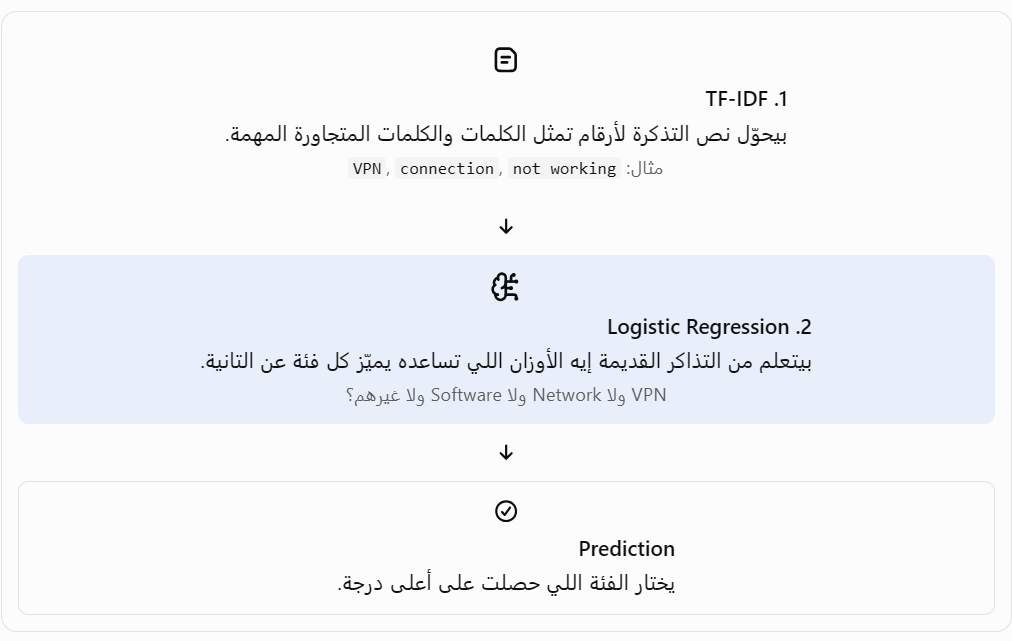

In [39]:
# Rebuild train / val / test from the saved ID files
# Why: every experiment from now on uses exactly the same split, even after a kernel restart.
from pathlib import Path

def load_ids(name):
    # One ticket_id per line -> a Python list of IDs
    return Path(f"data/splits/{name}_ids.txt").read_text(encoding="utf-8").split()

train = df[df["ticket_id"].isin(load_ids("train"))].reset_index(drop=True)
val   = df[df["ticket_id"].isin(load_ids("val"))].reset_index(drop=True)
test  = df[df["ticket_id"].isin(load_ids("test"))].reset_index(drop=True)
print(len(train), len(val), len(test))     # expected: 6512 1586 1451

6512 1586 1451


In [40]:
# Build the model input (title + description) and the target (L2 category)
# Why: the model may only see text the user wrote; labels and forbidden columns stay out.
def make_text(frame):
    return frame["title_ar"] + " . " + frame["description_ar"]

X_train, X_val = make_text(train), make_text(val)
y_train, y_val = train["category_level_2"], val["category_level_2"]

In [41]:
# Baseline: TF-IDF features + Logistic Regression, trained on train, scored on val
# Why: a simple, fast "ruler"; every Transformer later must beat this number.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2)   # single words + word pairs, seen in >= 2 tickets
X_train_vec = vectorizer.fit_transform(X_train)              # learn the vocabulary from TRAIN only
X_val_vec = vectorizer.transform(X_val)                      # reuse that same vocabulary for val

clf = LogisticRegression(max_iter=2000)                      # one weight per (word, class)
clf.fit(X_train_vec, y_train)                                # training = finding those weights

val_pred = clf.predict(X_val_vec)                            # predicted L2 for every val ticket
print("vocabulary size:", len(vectorizer.vocabulary_))
print("X_train_vec shape:", X_train_vec.shape)               # (number of tickets, vocabulary size)
print("val Macro-F1:", round(f1_score(y_val, val_pred, average="macro"), 3))

vocabulary size: 7534
X_train_vec shape: (6512, 7534)
val Macro-F1: 0.806


In [42]:
# Remove the leak sentence "فيه مشكلة مرتبطة بـ L1 / L2 / L3." from every description
# Why: it contains the label itself; a fair model must not see it.
import re
LEAK = re.compile(r"فيه مشكلة مرتبطة بـ[^.]*\.")      # from "فيه مشكلة مرتبطة بـ" up to the first "."

def clean_text(frame):
    desc = frame["description_ar"].str.replace(LEAK, "", regex=True)   # delete the leak sentence
    return frame["title_ar"] + " . " + desc

In [43]:
# Train TF-IDF + Logistic Regression on train and return Macro-F1 on val
# Why: we repeat the same experiment with different inputs, so we wrap it in one function.
def run_baseline(x_tr, y_tr, x_va, y_va):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
    model = LogisticRegression(max_iter=2000)
    model.fit(vec.fit_transform(x_tr), y_tr)                 # vocabulary + weights from train only
    pred = model.predict(vec.transform(x_va))
    return round(f1_score(y_va, pred, average="macro"), 3)

In [44]:
# Same model, 4 different inputs: what drives the score?
# Why: change ONE thing at a time, so any change in the score is caused by that thing.
results = {
    "1. raw (title + description)": run_baseline(make_text(train), y_train, make_text(val), y_val),
    "2. leak sentence removed":     run_baseline(clean_text(train), y_train, clean_text(val), y_val),
    "3. title only":                run_baseline(train["title_ar"], y_train, val["title_ar"], y_val),
    "4. description only":          run_baseline(train["description_ar"], y_train, val["description_ar"], y_val),
}
pd.Series(results)

1. raw (title + description)    0.806
2. leak sentence removed        0.785
3. title only                   0.773
4. description only             0.668
dtype: float64

In [45]:
# Can the text predict a label? Compare the real model with two "no-knowledge" references
# Why: if the model with real labels is no better than guessing, that label is not in the text.
from sklearn.dummy import DummyClassifier

def three_scores(y_tr, y_va):
    # Reference 1: random guesses that follow the class proportions (ignores the text)
    dummy = DummyClassifier(strategy="stratified", random_state=42).fit(X_train_vec, y_tr)
    guess = round(f1_score(y_va, dummy.predict(X_val_vec), average="macro"), 3)

    # Reference 2: same model, trained on SHUFFLED labels (every text-label link is destroyed)
    shuffled = y_tr.sample(frac=1, random_state=0).to_numpy()
    shuffled_f1 = run_baseline(X_train, shuffled, X_val, y_va)

    # The real test: same model, trained on the REAL labels
    real_f1 = run_baseline(X_train, y_tr, X_val, y_va)
    return {"random guessing": guess, "shuffled labels": shuffled_f1, "real labels": real_f1}

pd.DataFrame({
    "L2 category": three_scores(y_train, y_val),
    "urgency":     three_scores(train["urgency"], val["urgency"]),
})

,L2 category,urgency
random guessing,0.056,0.192
shuffled labels,0.065,0.205
real labels,0.806,0.206



. Urgency learnability (val Macro-F1): random 0.192 · shuffled labels 0.205 · real labels 0.206
    → urgency is NOT predictable from the text (L2 for comparison: 0.056 · 0.065 · 0.806). Finding 10 confirmed.

In [46]:
# Train the fair baseline (leak sentence removed) and keep its val predictions
# Why: error analysis should be done on the model we trust, not on the one that can cheat.
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
clf = LogisticRegression(max_iter=2000).fit(vec.fit_transform(clean_text(train)), y_train)
val_pred = clf.predict(vec.transform(clean_text(val)))

In [47]:
# Per-class report: precision, recall and F1 for each of the 16 L2 classes
# Why: Macro-F1 is just the average; this shows which classes are easy and which are hard.
from sklearn.metrics import classification_report
print(classification_report(y_val, val_pred, digits=3))

                   precision    recall  f1-score   support

          Account      0.780     0.885     0.829       156
     Business App      0.820     0.828     0.824        99
   Email/Calendar      0.979     0.495     0.657        93
         Incident      0.628     0.697     0.661       109
     Internet/LAN      0.714     0.833     0.769       102
   Laptop/Desktop      0.812     0.872     0.841        94
          MFA/SSO      0.645     0.690     0.667        71
 Malware/Phishing      0.692     0.857     0.766        84
      Office Apps      0.913     0.992     0.951       127
      Peripherals      0.875     0.726     0.794       106
      Permissions      0.851     0.741     0.792       108
Policy/Compliance      0.728     0.756     0.742        78
  Printer/Scanner      0.776     0.675     0.722        77
          Request      0.787     0.737     0.761        95
              VPN      0.822     0.815     0.819       108
             WiFi      0.974     0.949     0.962       

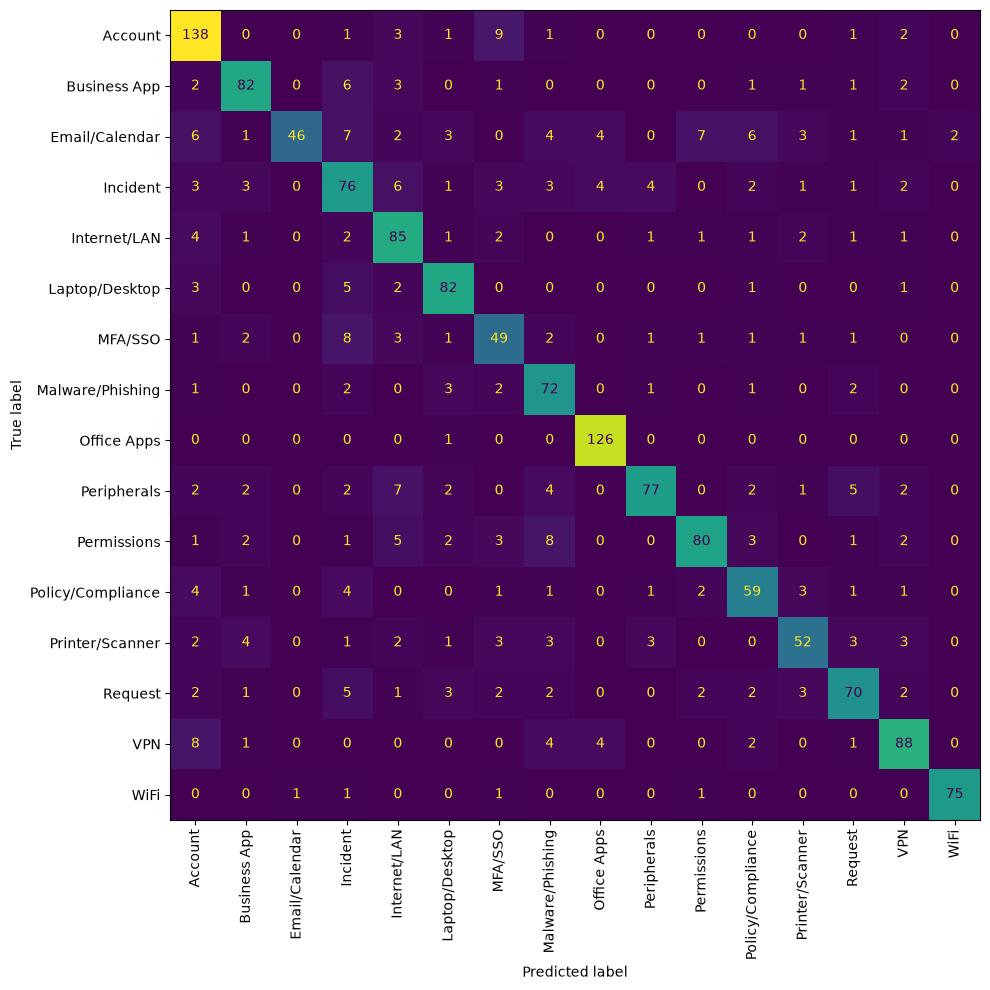

In [48]:
# Confusion matrix: rows = true class, columns = predicted class
# Why: shows WHICH classes the model mixes up, not only how often it is wrong.
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(y_val, val_pred, xticks_rotation=90, ax=ax, colorbar=False)
plt.tight_layout()
plt.show()

In [49]:
# Email/Calendar tickets the model got wrong: what do their titles actually say?
# Why: test the hypothesis that many are mislabeled (their text belongs to another class).
mask = (y_val == "Email/Calendar").to_numpy() & (val_pred != "Email/Calendar")
errors = val.loc[mask, ["ticket_id", "title_ar"]].assign(predicted=val_pred[mask])
print(mask.sum())          # how many Email/Calendar tickets were missed
errors.head(15)

47


,ticket_id,title_ar,predicted
171,TCKT-003-005,مشكلة سينك,Office Apps
177,TCKT-003-078,مشكلة سينك,Permissions
211,TCKT-003-294,مشكلة سينك,Laptop/Desktop
220,TCKT-003-378,مش قادر أفتح الميلبوكس,Laptop/Desktop
509,TCKT-007-086,مش عارف أدخل على الإيميل,Account
529,TCKT-007-191,مش عارف أدخل على الإيميل,Account
576,TCKT-007-494,مش عارف أدخل على الإيميل,Account
595,TCKT-008-108,الماوس بيعلق,Account
621,TCKT-008-302,فيروس على الجهاز,Malware/Phishing
638,TCKT-008-400,الايميل واقف,Policy/Compliance


In [50]:
# Were these words ever seen in training? (vocabulary of the fair baseline)
# Why: test whether the model failed because the words were new to it.
for w in ["سينك", "الميلبوكس", "الايميل", "الإيميل"]:
    print(w, "→ in train vocabulary:", w in vec.vocabulary_)

سينك → in train vocabulary: True
الميلبوكس → in train vocabulary: False
الايميل → in train vocabulary: True
الإيميل → in train vocabulary: True


In [51]:
# Error rate per generation batch (ticket_id prefix, e.g. "TCKT-008")
# Why: if a few batches have much higher error, their labels are probably scrambled.
batch = val["ticket_id"].str[:8]                              # "TCKT-008-108" → "TCKT-008"
wrong = pd.Series(val_pred != y_val.to_numpy(), index=val.index)
wrong.groupby(batch).mean().sort_values(ascending=False).round(2)

ticket_id
TCKT-008    0.77
TCKT-014    0.71
TCKT-011    0.65
TCKT-013    0.61
TCKT-020    0.24
TCKT-007    0.19
TCKT-012    0.18
TCKT-018    0.17
TCKT-003    0.17
TCKT-019    0.14
TCKT-006    0.13
TCKT-009    0.11
TCKT-015    0.06
TCKT-004    0.03
TCKT-005    0.01
TCKT-002    0.00
TCKT-001    0.00
TCKT-010    0.00
TCKT-016    0.00
TCKT-017    0.00
dtype: float64

In [52]:
 #Which L2 labels do TRAIN tickets containing "سينك" have?
# Why: the word WAS seen in training, so check what the model learned it means.
train_text = make_text(train)
train.loc[train_text.str.contains("سينك"), "category_level_2"].value_counts()


category_level_2
Email/Calendar    41
Name: count, dtype: int64

In [53]:
# How big are the suspicious batches in the whole de-duplicated dataset?
# Why: if they are large, scrambled labels would limit every model we train.
suspicious = ["TCKT-008", "TCKT-011", "TCKT-013", "TCKT-014"]
in_suspicious = df["ticket_id"].str[:8].isin(suspicious)
print(in_suspicious.sum(), "tickets =", round(in_suspicious.mean() * 100, 1), "% of the data")


1899 tickets = 19.9 % of the data


In [54]:
# Read 10 random tickets from the suspicious batches: does the title match the label?
# Why: numbers point to a problem; reading the tickets confirms (or rejects) it.
df.loc[in_suspicious, ["ticket_id", "title_ar", "category_level_2"]].sample(10, random_state=1)

,ticket_id,title_ar,category_level_2
5023,TCKT-011-162,عطل في النظام,Request
5128,TCKT-011-297,طلب دعم,Permissions
6252,TCKT-014-008,الاكسيل بيهنج,VPN
6583,TCKT-014-339,تغيير شاشة,Request
6633,TCKT-014-389,نقل ملفات,WiFi
5928,TCKT-013-184,اللابتوب بيعلق - 184,Request
6476,TCKT-014-232,عطل في الواي فاي,VPN
6329,TCKT-014-085,تحديث الاوفيس,Request
3604,TCKT-008-232,تحديث بيانات,Office Apps
5074,TCKT-011-220,السيستم واقع,Incident


In [55]:
# Remove the 4 batches with scrambled labels, then rerun the fair baseline once
# Why: a model cannot learn from (or be scored fairly on) wrong answers.
noisy = ["TCKT-008", "TCKT-011", "TCKT-013", "TCKT-014"]
train_c = train[~train["ticket_id"].str[:8].isin(noisy)]     # ~ means NOT: keep tickets outside these batches
val_c   = val[~val["ticket_id"].str[:8].isin(noisy)]
print(len(train_c), len(val_c))

score = run_baseline(clean_text(train_c), train_c["category_level_2"],
                     clean_text(val_c), val_c["category_level_2"])
print("fair baseline without noisy batches, val Macro-F1:", score)

5269 1251
fair baseline without noisy batches, val Macro-F1: 0.92


16. Batches TCKT-008/011/013/014 (1,899 tickets, 19.9%) have scrambled labels (61–77% val error vs ≤24% elsewhere).
    Fair baseline without them: val Macro-F1 = 0.92 (with them: 0.785) → the biggest data problem we found.

### Removing the noisy batches

**What we did**
- Error analysis showed 4 generation batches (TCKT-008, 011, 013, 014) where most labels do not match the ticket text
  (e.g. "الاكسيل بيهنج" → VPN, "عطل في الواي فاي" → VPN, "نقل ملفات" → WiFi).
- These batches hold 1,899 tickets (19.9% of the de-duplicated data).
- We removed them from train (6,512 → 5,269) and val (1,586 → 1,251) and retrained the SAME fair baseline
  (TF-IDF + Logistic Regression, leak sentence removed).

**Result**

| | val Macro-F1 |
|---|---|
| with noisy batches | 0.785 |
| without noisy batches | 0.920 |

**What it means**
- Wrong labels were the biggest problem in the data: the same model gains ~13.5 points once they are removed.
- Two effects are mixed: the model now learns from correct answers, AND it is graded with a correct answer key.
- 0.92 is still optimistic: shortcut phrases ("نسخة الأوفيس", "Error 809") are still in the text.
- From now on: use train/val without these batches (and remove them from test too when we use it).